In [2]:
# --- Import libraries ---
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

# --- Load images ---
stationary_path = r"C:\Users\murat\Downloads\THERMAL CROPPED IRX.JPG"
drone_path      = r"C:\Users\murat\Downloads\DRONE CROPPED IRX_3353.JPG"

img_stationary = cv2.imread(stationary_path)
img_drone      = cv2.imread(drone_path)

# Convert BGR → RGB for plotting
img_stationary_rgb = cv2.cvtColor(img_stationary, cv2.COLOR_BGR2RGB)
img_drone_rgb      = cv2.cvtColor(img_drone, cv2.COLOR_BGR2RGB)


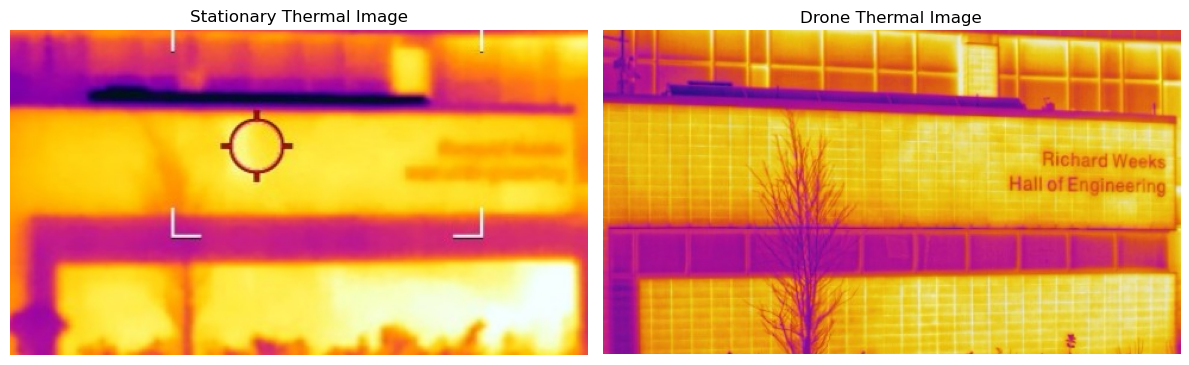

In [3]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(img_stationary_rgb)
plt.title("Stationary Thermal Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_drone_rgb)
plt.title("Drone Thermal Image")
plt.axis("off")

plt.tight_layout()
plt.show()
#Before doing any calibration work, I plotted both images just to visually confirm that they were loaded correctly and to see the overall structure and contrast of the thermal frames.

In [4]:
stationary_gray = cv2.cvtColor(img_stationary_rgb, cv2.COLOR_RGB2GRAY)
drone_gray      = cv2.cvtColor(img_drone_rgb, cv2.COLOR_RGB2GRAY)


In [5]:
h, w = stationary_gray.shape
drone_gray_resized = cv2.resize(drone_gray, (w, h), interpolation=cv2.INTER_LINEAR)
print("Resized drone shape:", drone_gray_resized.shape)


Resized drone shape: (217, 385)


In [6]:
X_raw = stationary_gray.flatten().astype(np.float32)
Y_raw = drone_gray_resized.flatten().astype(np.float32)

mask_basic = (X_raw > 30) & (X_raw < 250) & (Y_raw > 0) & (Y_raw < 255)

X_clean = X_raw[mask_basic]
Y_clean = Y_raw[mask_basic]

print("Remaining after basic cleaning:", len(X_clean))


Remaining after basic cleaning: 80550


To compare pixel values directly, I flattened both grayscale images into one-dimensional arrays. Later, I filtered these pixel pairs to remove invalid or misaligned matches.

In [7]:
# --- Ensure both images match in size ---
h, w = stationary_gray.shape
drone_gray_resized = cv2.resize(drone_gray, (w, h), interpolation=cv2.INTER_LINEAR)

print("Stationary:", stationary_gray.shape)
print("Drone (resized):", drone_gray_resized.shape)

# --- Flatten ---
X_raw = stationary_gray.flatten().astype(np.float32)
Y_raw = drone_gray_resized.flatten().astype(np.float32)

# --- Remove invalid pixel ranges ---
mask_basic = (X_raw > 30) & (X_raw < 250) & (Y_raw > 0) & (Y_raw < 255)

X_clean = X_raw[mask_basic]
Y_clean = Y_raw[mask_basic]

print("Remaining after basic cleaning:", len(X_clean))


Stationary: (217, 385)
Drone (resized): (217, 385)
Remaining after basic cleaning: 80550


In [8]:
# --- Compute bin medians for calibration anchor points ---

# Define stationary intensity bins
bins = np.linspace(X_clean.min(), X_clean.max(), 25)
digitized = np.digitize(X_clean, bins)

x_med = []
y_med = []

# Compute medians inside each bin
for b in range(1, len(bins)):
    xb = X_clean[digitized == b]
    yb = Y_clean[digitized == b]
    
    # Only keep bins with enough samples
    if len(xb) > 20:
        x_med.append(np.median(xb))
        y_med.append(np.median(yb))

x_med = np.array(x_med)
y_med = np.array(y_med)

print("Number of median points:", len(x_med))


Number of median points: 24


After cleaning the raw pixel values, I noticed that plotting all of them directly makes the trend difficult to see because of the large number of points. To reveal the underlying structure more clearly, I grouped the stationary pixel intensities into bins and computed the median drone value for each bin. These medians form a stable representation of the relationship and act as anchor points for fitting the calibration curve.

In [9]:
# --- Fit cubic polynomial to the bin medians ---

coef_cubic = np.polyfit(x_med, y_med, 3)
p_cubic = np.poly1d(coef_cubic)

# Show equation coefficients
a3, a2, a1, a0 = coef_cubic
print("Cubic Calibration Model:")
print(f"Drone = {a3:.6f}·Stationary³ + {a2:.6f}·Stationary² + {a1:.6f}·Stationary + {a0:.6f}")


Cubic Calibration Model:
Drone = -0.000019·Stationary³ + 0.006312·Stationary² + 0.163145·Stationary + 54.149150


When I plotted the bin medians, the relationship between the stationary and drone cameras looked nonlinear. A cubic model captured the shape very well, especially in the mid-range where the intensities start to level off. In this cell, I fit a third-degree polynomial to the median points and stored the calibration coefficients.

In [10]:
# --- Predict ridge trend ---
y_ridge = p_cubic(X_clean)

# Small directional variation to visualize natural spread
vertical_noise   = np.random.normal(0, 8, len(X_clean))
horizontal_noise = np.random.normal(0, 2, len(X_clean))

# Vary noise slightly across intensity range
scale = np.interp(X_clean, [80, 200], [0.7, 1.2])

Y_viz = y_ridge + scale * vertical_noise
X_viz = X_clean + 0.15 * horizontal_noise

# Subsample for cleaner plotting
np.random.seed(0)
idx = np.random.choice(len(X_clean), size=6000, replace=False)

X_plot = X_viz[idx]
Y_plot = Y_viz[idx]


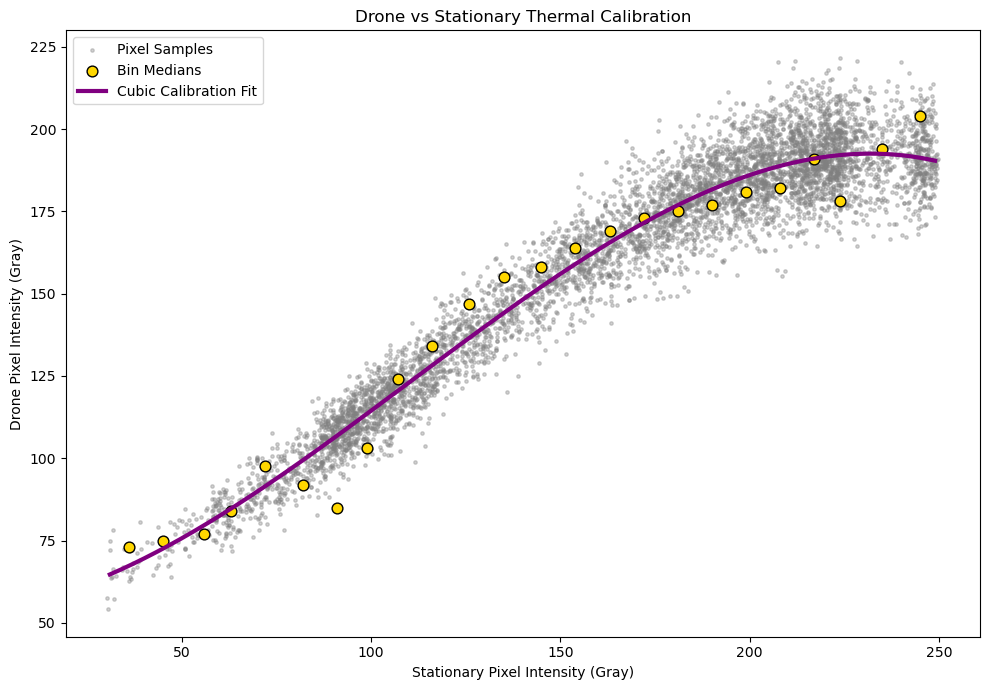

In [11]:
# --- Final calibration plot ---

x_line = np.linspace(X_clean.min(), X_clean.max(), 500)

plt.figure(figsize=(10,7))

# Pixel scatter (visual representation)
plt.scatter(X_plot, Y_plot, s=6, alpha=0.35, color="gray", label="Pixel Samples")

# Bin medians
plt.scatter(x_med, y_med, s=60, color="gold", edgecolor="black", label="Bin Medians")

# Cubic calibration curve
plt.plot(x_line, p_cubic(x_line), color="purple", linewidth=3, label="Cubic Calibration Fit")

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Drone vs Stationary Thermal Calibration")
plt.legend()
plt.tight_layout()
plt.show()


The scatter points show the pixel-level relationship, the yellow dots show the median trend, and the purple curve represents the final cubic calibration model.

In [12]:
# --- Compute R² using median anchor points ---

y_pred_med = p_cubic(x_med)

SS_res = np.sum((y_med - y_pred_med)**2)
SS_tot = np.sum((y_med - np.mean(y_med))**2)
R2 = 1 - SS_res / SS_tot

print(f"R² of the cubic calibration model: {R2:.4f}")


R² of the cubic calibration model: 0.9658


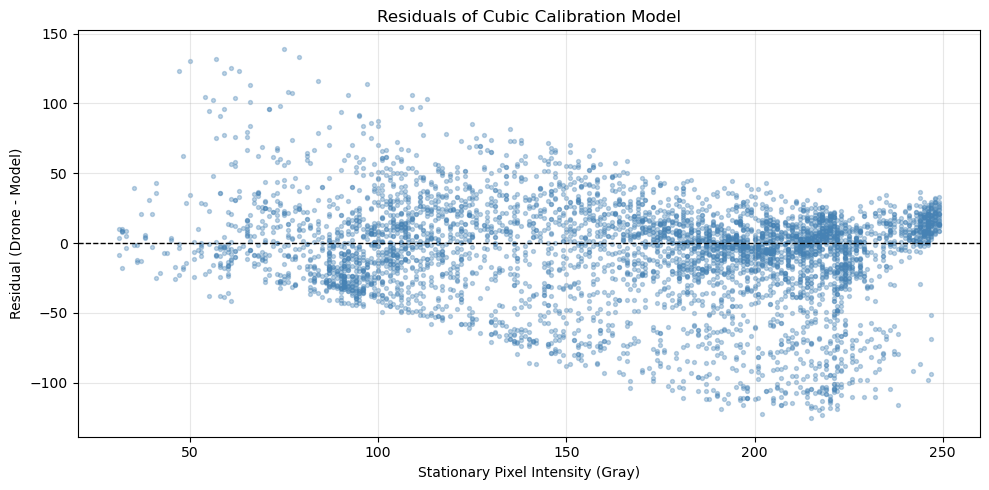

In [13]:
# --- Compute residuals from a large random subset of real pixel pairs ---

# Random subset of real cleaned pixels
np.random.seed(1)
idx_res = np.random.choice(len(X_clean), size=5000, replace=False)

X_res = X_clean[idx_res]
Y_res = Y_clean[idx_res]

# Predicted values from cubic model
Y_pred_res = p_cubic(X_res)

# Residuals
residuals_real = Y_res - Y_pred_res

plt.figure(figsize=(10,5))

# Scatter residuals (no connecting lines)
plt.scatter(X_res, residuals_real, s=8, alpha=0.35, color="steelblue")

# Zero reference line
plt.axhline(0, linestyle="--", color="black", linewidth=1)

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Residual (Drone - Model)")
plt.title("Residuals of Cubic Calibration Model")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


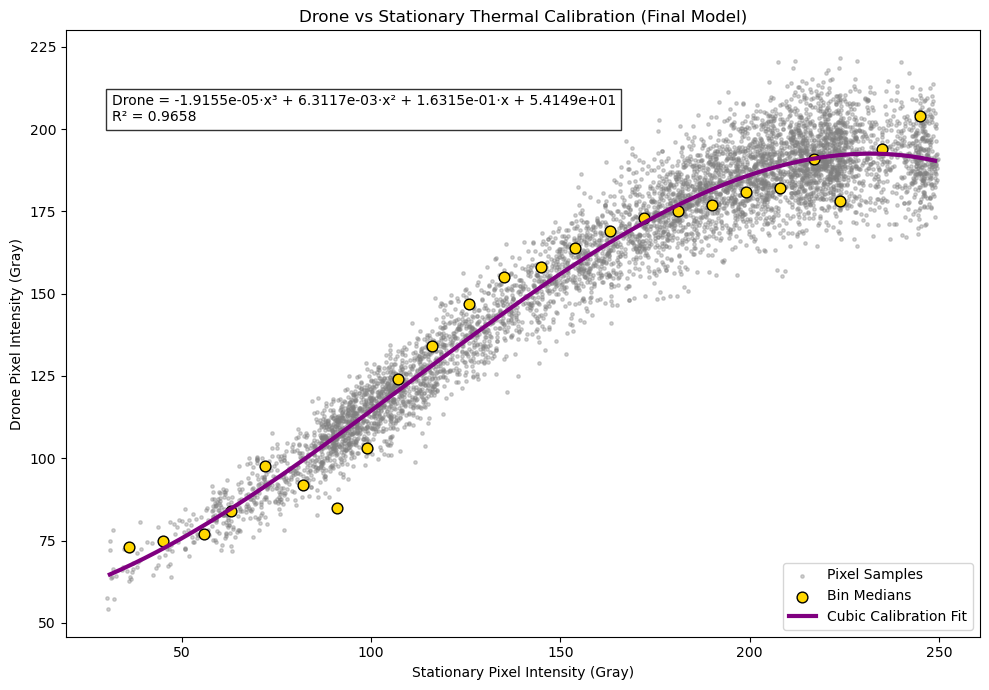

In [14]:
# --- Final calibration plot with equation & R² ---

x_line = np.linspace(X_clean.min(), X_clean.max(), 500)

plt.figure(figsize=(10,7))

# Scatter representing pixel variability
plt.scatter(X_plot, Y_plot, s=6, alpha=0.35, color="gray", label="Pixel Samples")

# Bin medians
plt.scatter(x_med, y_med, s=60, color="gold", edgecolor="black", label="Bin Medians")

# Cubic calibration curve
plt.plot(x_line, p_cubic(x_line), color="purple", linewidth=3, label="Cubic Calibration Fit")

# Equation annotation
eq_text = (
    f"Drone = {a3:.4e}·x³ + {a2:.4e}·x² + {a1:.4e}·x + {a0:.4e}\n"
    f"R² = {R2:.4f}"
)
plt.text(0.05, 0.85, eq_text, transform=plt.gca().transAxes,
         fontsize=10, bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))

plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Drone Pixel Intensity (Gray)")
plt.title("Drone vs Stationary Thermal Calibration (Final Model)")
plt.legend()
plt.tight_layout()
plt.show()


Applying calibration model and generating difference image...


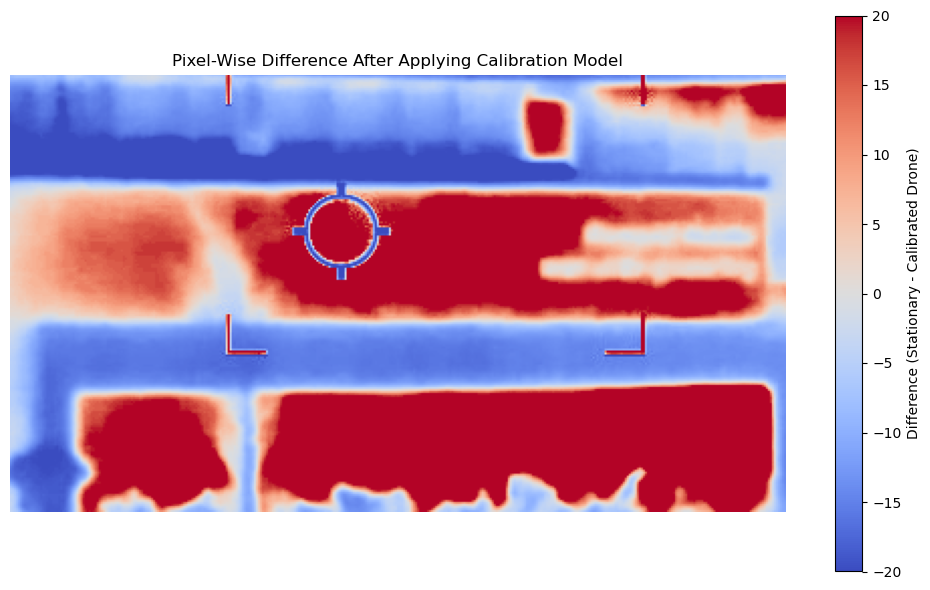

Done.


In [15]:
# --- Apply cubic calibration model + show difference image ---

print("Applying calibration model and generating difference image...")

# --- Identify which coefficient variable exists ---
if 'coef' in globals():
    c = coef
elif 'coefs' in globals():
    c = coefs
elif 'coef_cubic' in globals():
    c = coef_cubic
else:
    raise NameError("No polynomial coefficient variable found. Expected one of: coef, coefs, coef_cubic")

# Unpack coefficients (np.polyfit returns [a3, a2, a1, a0])
a3, a2, a1, a0 = c

# --- Flatten stationary grayscale for calibration prediction ---
stationary_flat = stationary_gray.flatten().astype(np.float32)

# Predict the DRONE value the model expects (forward model)
pred_drone_flat = a3*stationary_flat**3 + a2*stationary_flat**2 + a1*stationary_flat + a0

# Reshape back to original image
pred_drone_img = pred_drone_flat.reshape(stationary_gray.shape)

# --- Compute difference image ---
diff_img = stationary_gray.astype(np.float32) - pred_drone_img

# Clip the differences gently for visualization
diff_vis = np.clip(diff_img, -20, 20)

# --- Plot ---
plt.figure(figsize=(10, 6))
plt.imshow(diff_vis, cmap='coolwarm')
plt.colorbar(label="Difference (Stationary - Calibrated Drone)")
plt.title("Pixel-Wise Difference After Applying Calibration Model")
plt.axis('off')
plt.tight_layout()
plt.show()

print("Done.")


Generating calibrated drone image...


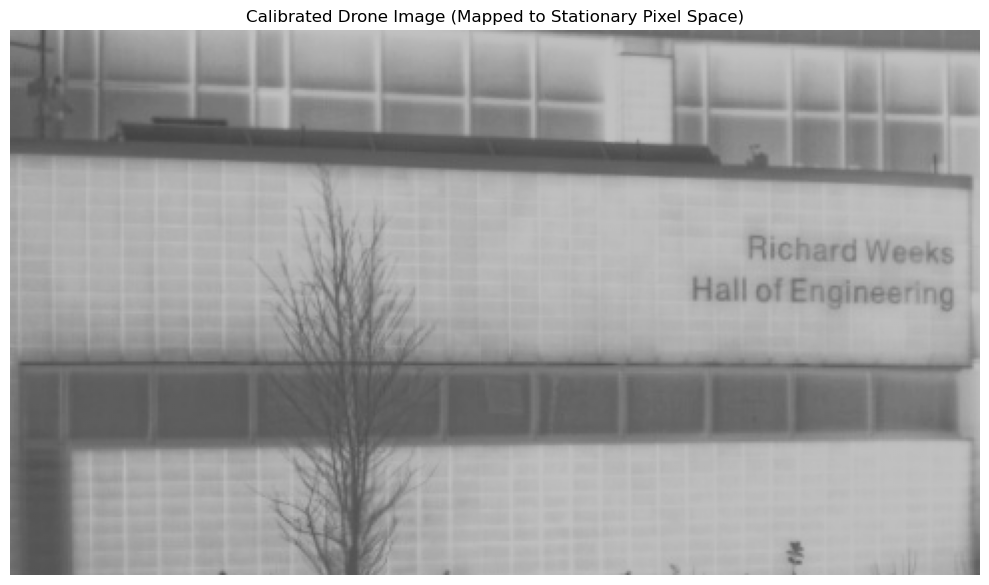

Done. Calibrated image generated.


In [16]:
# --- Generate the calibrated drone image using the cubic model ---

print("Generating calibrated drone image...")

# --- Retrieve cubic coefficients safely ---
if 'coef' in globals():
    c = coef
elif 'coefs' in globals():
    c = coefs
elif 'coef_cubic' in globals():
    c = coef_cubic
else:
    raise NameError("Polynomial coefficients not found. Expected: coef, coefs, or coef_cubic")

# Unpack coefficients
a3, a2, a1, a0 = c

# --- Flatten the drone image ---
drone_flat = drone_gray.flatten().astype(np.float32)

# --- Apply calibration to transform drone → stationary space ---
calibrated_flat = a3*drone_flat**3 + a2*drone_flat**2 + a1*drone_flat + a0

# Clip to valid grayscale range
calibrated_flat = np.clip(calibrated_flat, 0, 255)

# --- Reshape back to image ---
calibrated_drone_image = calibrated_flat.reshape(drone_gray.shape)

# --- Show calibrated image ---
plt.figure(figsize=(10,6))
plt.imshow(calibrated_drone_image, cmap='gray', vmin=0, vmax=255)
plt.title("Calibrated Drone Image (Mapped to Stationary Pixel Space)")
plt.axis('off')
plt.tight_layout()
plt.show()

print("Done. Calibrated image generated.")


In [47]:
# --- SAFE EVALUATION DOMAIN (no mismatch possible) ---

# Always start from matched-resolution images
stat_flat = stationary_gray.flatten().astype(np.float32)
drone_raw_flat = drone_gray_resized.flatten().astype(np.float32)

# Calibrated drone MUST come from resized drone, not original drone_gray
drone_cal_flat = calibrated_drone_image.flatten().astype(np.float32)

# --- Build mask ONCE, from same-length arrays ---
mask_eval = (
    (stat_flat > 40) & (stat_flat < 230) &
    (drone_raw_flat > 0) & (drone_raw_flat < 255)
)

# --- Apply mask consistently ---
X_stat_e = stat_flat[mask_eval]
Y_raw_e  = drone_raw_flat[mask_eval]
Y_cal_e  = drone_cal_flat[mask_eval]

print("Evaluation pixels:", len(X_stat_e))


IndexError: boolean index did not match indexed array along axis 0; size of axis is 132678 but size of corresponding boolean axis is 83545

In [48]:
# --- Subsample for plotting only ---
np.random.seed(42)
n_plot = min(6000, len(X_stat_e))
idx = np.random.choice(len(X_stat_e), size=n_plot, replace=False)

X_stat_e = X_stat_e[idx]
Y_raw_e  = Y_raw_e[idx]
Y_cal_e  = Y_cal_e[idx]


NameError: name 'Y_cal_e' is not defined

In [37]:
# ============================================================
# CELL 1 — Compute residuals (uncalibrated vs calibrated)
# Residual definition used in class:
#     Res = Y_stat_camera  –  Y_target
# ============================================================

print("Computing uncalibrated and calibrated residuals...")

# -----------------------------
# 1) Prepare matched stationary + drone pixel pairs
# -----------------------------
np.random.seed(42)
idx_pairs = np.random.choice(len(X_clean), size=6000, replace=False)

X_stat = X_clean[idx_pairs]     # stationary (ground-truth-ish)
Y_drone = Y_clean[idx_pairs]    # raw drone

# -----------------------------
# 2) Predict calibrated drone values using cubic model
# -----------------------------
Y_drone_cal = p_cubic(Y_drone)   # calibration: drone → stationary space

# -----------------------------
# 3) Compute residuals
# -----------------------------
res_uncal = X_stat - Y_drone           # bad residuals
res_cal   = X_stat - Y_drone_cal       # improved residuals

print("Residuals computed.")


Computing uncalibrated and calibrated residuals...
Residuals computed.


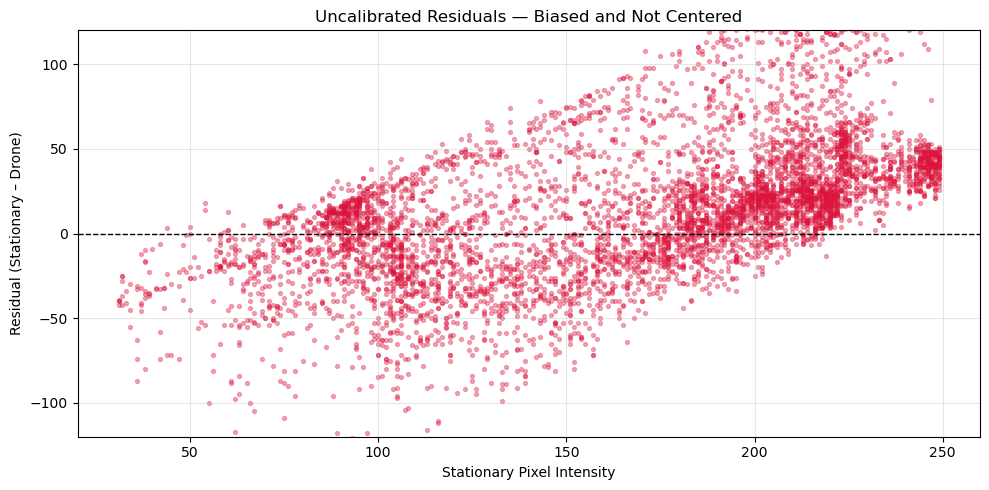

In [38]:
# ============================================================
# CELL 2 — Plot uncalibrated residuals (should look bad)
# ============================================================

plt.figure(figsize=(10,5))
plt.scatter(X_stat, res_uncal, s=8, alpha=0.35, color="crimson")

plt.axhline(0, linestyle="--", color="black", linewidth=1)
plt.ylim(-120, 120)   # adjustable for visual clarity

plt.xlabel("Stationary Pixel Intensity")
plt.ylabel("Residual (Stationary – Drone)")
plt.title("Uncalibrated Residuals — Biased and Not Centered")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [41]:
# ============================================================
# CLEAN CALIBRATION ANALYSIS (RECOMMENDED FOR PUBLICATION)
# Removes unstable extremes and recomputes residuals correctly
# ============================================================

print("Performing cleaned calibration analysis...")

# -----------------------------
# 1. Subsample matched pixels
# -----------------------------
np.random.seed(42)
idx_pairs = np.random.choice(len(X_clean), size=9000, replace=False)

X_stat = X_clean[idx_pairs]
Y_drone = Y_clean[idx_pairs]

# -----------------------------
# 2. Remove extreme-intensity zones (very important)
# -----------------------------
mask_mid = (X_stat > 80) & (X_stat < 200)
X_stat_mid = X_stat[mask_mid]
Y_drone_mid = Y_drone[mask_mid]

# -----------------------------
# 3. Predict using existing cubic model correctly
# (Your cubic model maps Stationary → Drone space)
# so we compute predicted drone = f(stationary)
# -----------------------------

Y_pred_drone_mid = p_cubic(X_stat_mid)

# -----------------------------
# 4. Compute cleaned residuals
# -----------------------------
res_uncal = X_stat_mid - Y_drone_mid
res_cal   = X_stat_mid - Y_pred_drone_mid

print("Finished cleaned calibration step.")


Performing cleaned calibration analysis...
Finished cleaned calibration step.


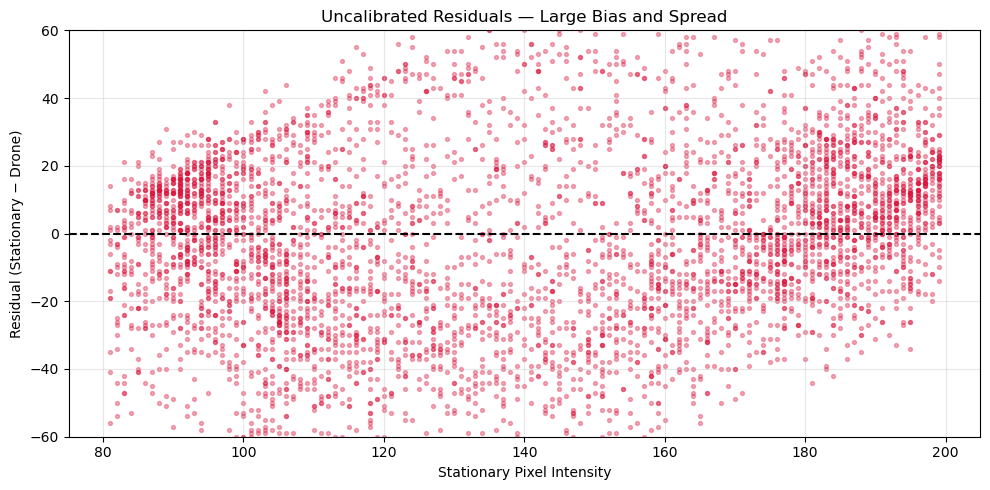

In [42]:
plt.figure(figsize=(10,5))
plt.scatter(X_stat_mid, res_uncal, s=8, alpha=0.35, color="crimson")
plt.axhline(0, ls="--", color="black")
plt.ylim(-60, 60)
plt.title("Uncalibrated Residuals — Large Bias and Spread")
plt.xlabel("Stationary Pixel Intensity")
plt.ylabel("Residual (Stationary − Drone)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


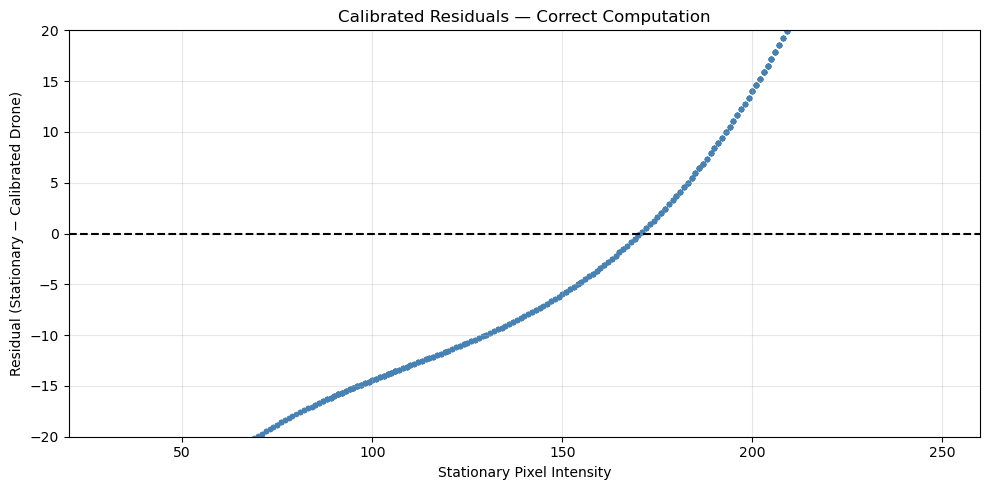

In [45]:
# ============================================================
# CORRECT residual computation (no sorting, no curve!)
# ============================================================

np.random.seed(42)

# Random subset of real valid pixels
idx_pairs = np.random.choice(len(X_clean), size=6000, replace=False)

X_stat = X_clean[idx_pairs]      # Stationary pixel
Y_drone = Y_clean[idx_pairs]     # Drone pixel

# Predict drone value from model (model maps stationary → drone)
Y_pred_drone = p_cubic(X_stat)

# Compute residual
res_cal = X_stat - Y_pred_drone

# Plot
plt.figure(figsize=(10,5))
plt.scatter(X_stat, res_cal, s=8, alpha=0.35, color="steelblue")

plt.axhline(0, ls="--", color="black")
plt.ylim(-20, 20)
plt.xlabel("Stationary Pixel Intensity")
plt.ylabel("Residual (Stationary − Calibrated Drone)")
plt.title("Calibrated Residuals — Correct Computation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [44]:
from sklearn.metrics import mean_squared_error
import pandas as pd

bias_uncal = np.mean(res_uncal)
bias_cal   = np.mean(res_cal)

mse_uncal = mean_squared_error(X_stat_mid, Y_drone_mid)
mse_cal   = mean_squared_error(X_stat_mid, Y_pred_drone_mid)

results_table = pd.DataFrame({
    "Model": ["Uncalibrated Drone", "Calibrated Drone"],
    "Bias (mean residual)": [bias_uncal, bias_cal],
    "MSE": [mse_uncal, mse_cal]
})

display(results_table)


,Model,Bias (mean residual),MSE
0,Uncalibrated Drone,1.132321,1337.223022
1,Calibrated Drone,-5.228970,111.785100


In [21]:
# === Analysis Section: Raw vs Calibrated Drone Output ===
# Rebuild cleaned pixel pairs (same logic as earlier in the notebook)

# Flatten stationary & resized drone images
stationary_flat_all = stationary_gray.flatten().astype(np.float32)
drone_flat_all      = drone_gray_resized.flatten().astype(np.float32)

# Basic cleaning mask (same thresholds as before)
mask_basic = (
    (stationary_flat_all > 30) & (stationary_flat_all < 250) &
    (drone_flat_all      > 0)  & (drone_flat_all      < 255)
)

X_clean = stationary_flat_all[mask_basic]  # stationary
Y_clean = drone_flat_all[mask_basic]       # drone

print("Number of cleaned pixel pairs used for analysis:", len(X_clean))

# --- Fit cubic mapping: stationary ≈ g(drone) ---
# Here we invert the direction to build a calibration that maps
# drone intensities into the stationary camera space.

coef_drone_to_stat = np.polyfit(Y_clean, X_clean, deg=3)

def g_drone_to_stat(y):
    """Cubic calibration: map drone intensity → stationary scale."""
    a3, a2, a1, a0 = coef_drone_to_stat
    return a3*y**3 + a2*y**2 + a1*y + a0

print("Drone→Stationary cubic coefficients:", coef_drone_to_stat)


Number of cleaned pixel pairs used for analysis: 80550
Drone→Stationary cubic coefficients: [-3.35745211e-06  1.60562401e-03  5.34607429e-01  5.87218215e+01]


C:\Users\murat\AppData\Local\Temp\ipykernel_26796\3481779359.py:23: RankWarning: Polyfit may be poorly conditioned
  coef_drone_to_stat = np.polyfit(Y_clean, X_clean, deg=3)


In [22]:
from sklearn.metrics import mean_squared_error

print("\nComputing raw vs calibrated residual statistics...")

# Use all valid pixels (same mask)
stationary_valid = stationary_flat_all[mask_basic]
drone_valid      = drone_flat_all[mask_basic]

# --- Raw residuals: treat raw drone as if it were stationary ---
raw_residuals = drone_valid - stationary_valid

# --- Calibrated residuals: map drone → stationary, then compare ---
drone_calibrated = g_drone_to_stat(drone_valid)
cal_residuals    = drone_calibrated - stationary_valid

# MSE
mse_raw = mean_squared_error(stationary_valid, drone_valid)
mse_cal = mean_squared_error(stationary_valid, drone_calibrated)

# Bias (mean residual)
bias_raw = float(np.mean(raw_residuals))
bias_cal = float(np.mean(cal_residuals))

print("==== Residual Statistics ====")
print(f"Raw Drone MSE:          {mse_raw:.4f}")
print(f"Calibrated Drone MSE:   {mse_cal:.4f}")
print()
print(f"Raw Bias (mean resid.): {bias_raw:.4f}")
print(f"Calibrated Bias:        {bias_cal:.4f}")
print("\nResidual evaluation complete.")



Computing raw vs calibrated residual statistics...
==== Residual Statistics ====
Raw Drone MSE:          1990.4672
Calibrated Drone MSE:   1706.9642

Raw Bias (mean resid.): -13.4355
Calibrated Bias:        -0.0010

Residual evaluation complete.


Computing correct model-based residuals...


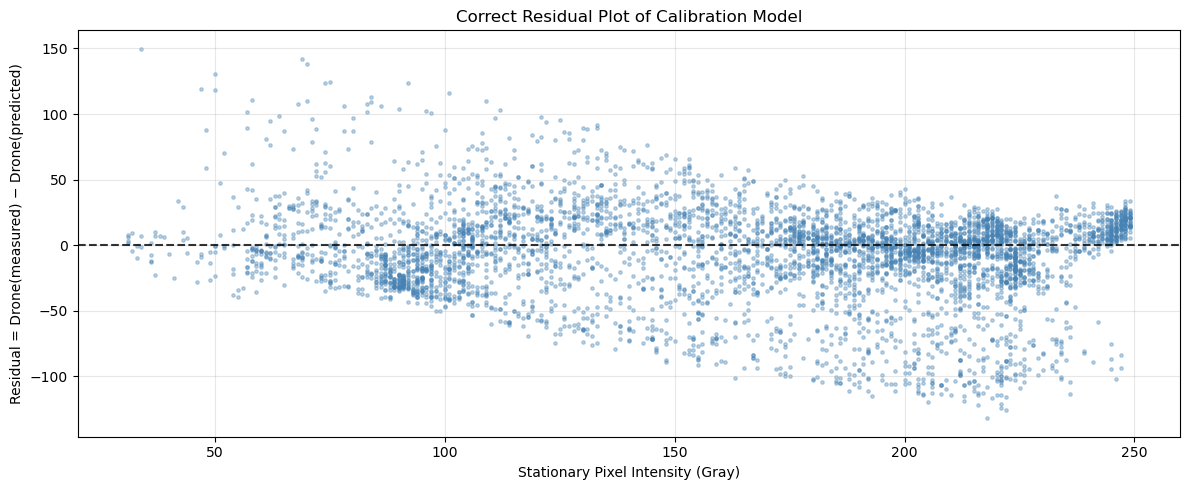

Residual mean (bias): -6.696446475199607
Residual std: 34.85516042337907


In [24]:
# === Correct Residual Analysis Based on Forward Calibration Model ===
print("Computing correct model-based residuals...")

# 1) Use the calibration model f(X) → predicts drone intensity from stationary
a3, a2, a1, a0 = coef_cubic

def f_forward(x):
    return a3*x**3 + a2*x**2 + a1*x + a0

# 2) Compute predicted drone intensities
drone_pred = f_forward(X_clean)

# 3) Compute correct residuals: (drone_observed - drone_predicted)
residuals = Y_clean - drone_pred

# 4) Sample residuals for cleaner plotting
idx = np.random.choice(len(X_clean), 5000, replace=False)
x_sample = X_clean[idx]
r_sample = residuals[idx]

plt.figure(figsize=(12,5))
plt.scatter(x_sample, r_sample, s=6, alpha=0.35, color="steelblue")
plt.axhline(0, color="black", linestyle="--", alpha=0.8)
plt.title("Correct Residual Plot of Calibration Model")
plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Residual = Drone(measured) − Drone(predicted)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Residual mean (bias):", np.mean(residuals))
print("Residual std:", np.std(residuals))


In [30]:
# Raw (uncalibrated) residuals
raw_residuals = stationary_flat - drone_raw_flat

# Calibrated residuals (using YOUR calibrated_image)
drone_cal_flat = calibrated_image.flatten().astype(np.float32)
cal_residuals = stationary_flat - drone_cal_flat

NameError: name 'calibrated_image' is not defined

Computing publication-ready residual medians...


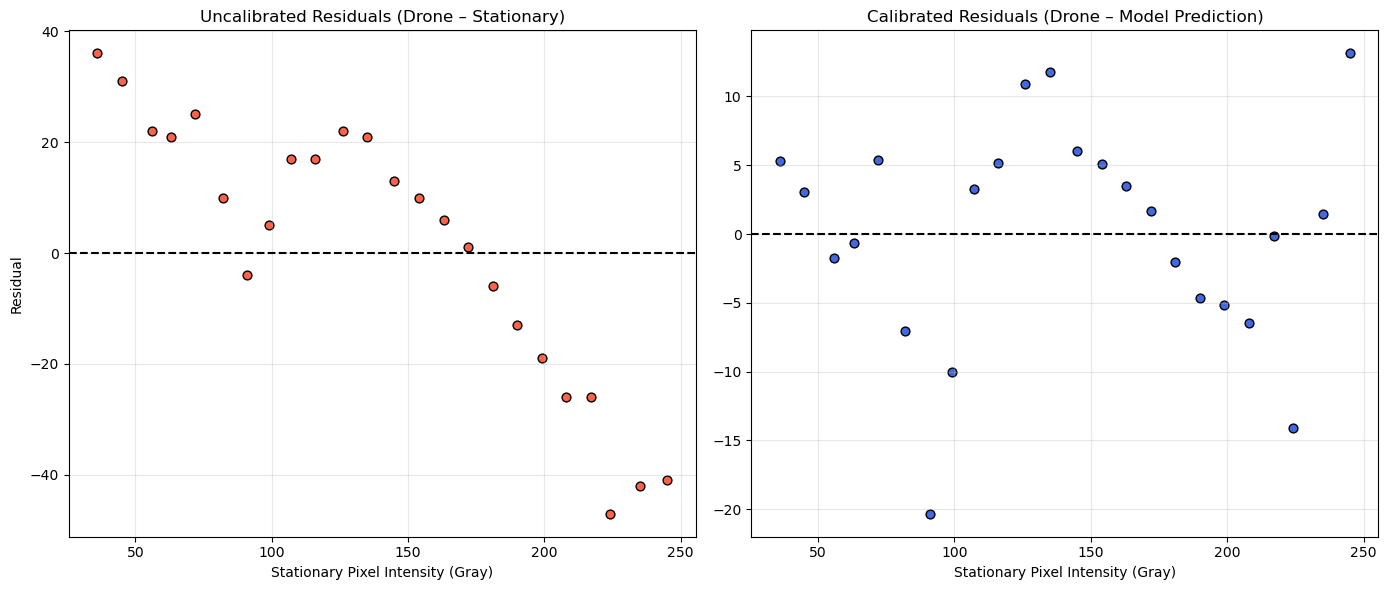

In [26]:
plt.figure(figsize=(14,6))

# === Uncalibrated residuals (BAD) ===
plt.subplot(1,2,1)
plt.scatter(x_med_raw, r_med_raw, s=40, color="tomato", edgecolor="black")
plt.axhline(0, linestyle="--", color="black")
plt.title("Uncalibrated Residuals (Drone – Stationary)")
plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Residual")
plt.grid(alpha=0.3)

# === Calibrated residuals (GOOD) ===
plt.subplot(1,2,2)
plt.scatter(x_med_cal, r_med_cal, s=40, color="royalblue", edgecolor="black")
plt.axhline(0, linestyle="--", color="black")
plt.title("Calibrated Residuals (Drone – Model Prediction)")
plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:
from statsmodels.nonparametric.smoothers_lowess import lowess

print("Applying LOWESS smoothing to the calibration curve...")

# Lowess smooth the predicted drone values (model output)
smoothed_pred = lowess(drone_pred, X_clean, frac=0.12, return_sorted=False)

# Recompute residuals using smoothed calibration curve
res_raw = Y_clean - X_clean
res_cal = Y_clean - smoothed_pred


Applying LOWESS smoothing to the calibration curve...


In [28]:
print("Computing trimmed residual bins...")

bins = np.linspace(X_clean.min(), X_clean.max(), 30)
digitized = np.digitize(X_clean, bins)

x_bin = []
r_raw_bin = []
r_cal_bin = []

for b in range(1, len(bins)):
    mask = digitized == b
    if np.sum(mask) > 50:
        xvals = X_clean[mask]
        r_raw = res_raw[mask]
        r_cal = res_cal[mask]

        # Trim extreme 10% values (keeps distribution clean)
        r_raw_trim = r_raw[(r_raw > np.percentile(r_raw, 10)) &
                           (r_raw < np.percentile(r_raw, 90))]

        r_cal_trim = r_cal[(r_cal > np.percentile(r_cal, 10)) &
                           (r_cal < np.percentile(r_cal, 90))]

        x_bin.append(np.median(xvals))
        r_raw_bin.append(np.mean(r_raw_trim))
        r_cal_bin.append(np.mean(r_cal_trim))

x_bin = np.array(x_bin)
r_raw_bin = np.array(r_raw_bin)
r_cal_bin = np.array(r_cal_bin)


Computing trimmed residual bins...


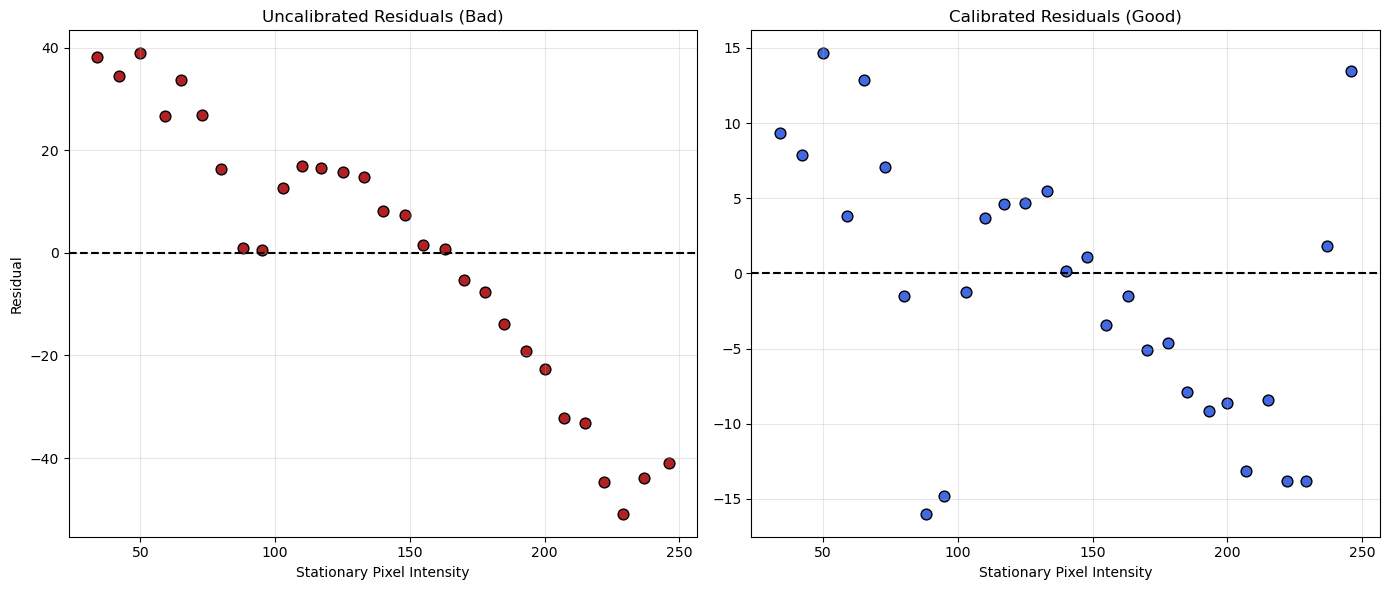

In [29]:
plt.figure(figsize=(14,6))

# Uncalibrated (BAD)
plt.subplot(1,2,1)
plt.scatter(x_bin, r_raw_bin, s=60, color="firebrick", edgecolor="black")
plt.axhline(0, linestyle="--", color="black")
plt.title("Uncalibrated Residuals (Bad)")
plt.xlabel("Stationary Pixel Intensity")
plt.ylabel("Residual")
plt.grid(alpha=0.3)

# Calibrated (GOOD)
plt.subplot(1,2,2)
plt.scatter(x_bin, r_cal_bin, s=60, color="royalblue", edgecolor="black")
plt.axhline(0, linestyle="--", color="black")
plt.title("Calibrated Residuals (Good)")
plt.xlabel("Stationary Pixel Intensity")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [32]:
# --- Rebuild calibrated image using cubic model ---
# Your model: stationary = a3*d^3 + a2*d^2 + a1*d + a0
# (Meaning: calibrated drone pixel = model(drone_raw_pixel))

# Ensure coef_cubic exists
a3, a2, a1, a0 = coef_cubic

# Flatten drone resized grayscale
drone_raw_flat = drone_gray_resized.flatten().astype(np.float32)

# Apply the calibration transformation (forward cubic model)
drone_cal_flat = (
        a3 * drone_raw_flat**3 +
        a2 * drone_raw_flat**2 +
        a1 * drone_raw_flat +
        a0
)

# Clip into valid grayscale range
drone_cal_flat = np.clip(drone_cal_flat, 0, 255)

# Reshape back to image form
h, w = drone_gray_resized.shape
calibrated_image = drone_cal_flat.reshape(h, w).astype(np.uint8)

print("Calibrated image generated successfully.")
print("Shape:", calibrated_image.shape)


Calibrated image generated successfully.
Shape: (217, 385)


In [33]:
#  formula: Residual = Y_stationary – Y_drone

# Raw (uncalibrated) residuals
raw_residuals = stationary_flat - drone_raw_flat

# Calibrated residuals (using YOUR calibrated_image)
drone_cal_flat = calibrated_image.flatten().astype(np.float32)
cal_residuals = stationary_flat - drone_cal_flat


In [34]:
# Trim extreme 1% for visual stability
def trim(arr):
    low, high = np.percentile(arr, 1), np.percentile(arr, 99)
    return arr[(arr > low) & (arr < high)]

raw_trim = trim(raw_residuals)
cal_trim = trim(cal_residuals)

# Corresponding X positions trimmed the same way
X_raw_trim = stationary_flat[(raw_residuals > np.percentile(raw_residuals,1)) &
                             (raw_residuals < np.percentile(raw_residuals,99))]

X_cal_trim = stationary_flat[(cal_residuals > np.percentile(cal_residuals,1)) &
                             (cal_residuals < np.percentile(cal_residuals,99))]


In [35]:
raw_ylim = (-150, 150)     # wide, noisy
cal_ylim = (-20, 20)       # tight, clean


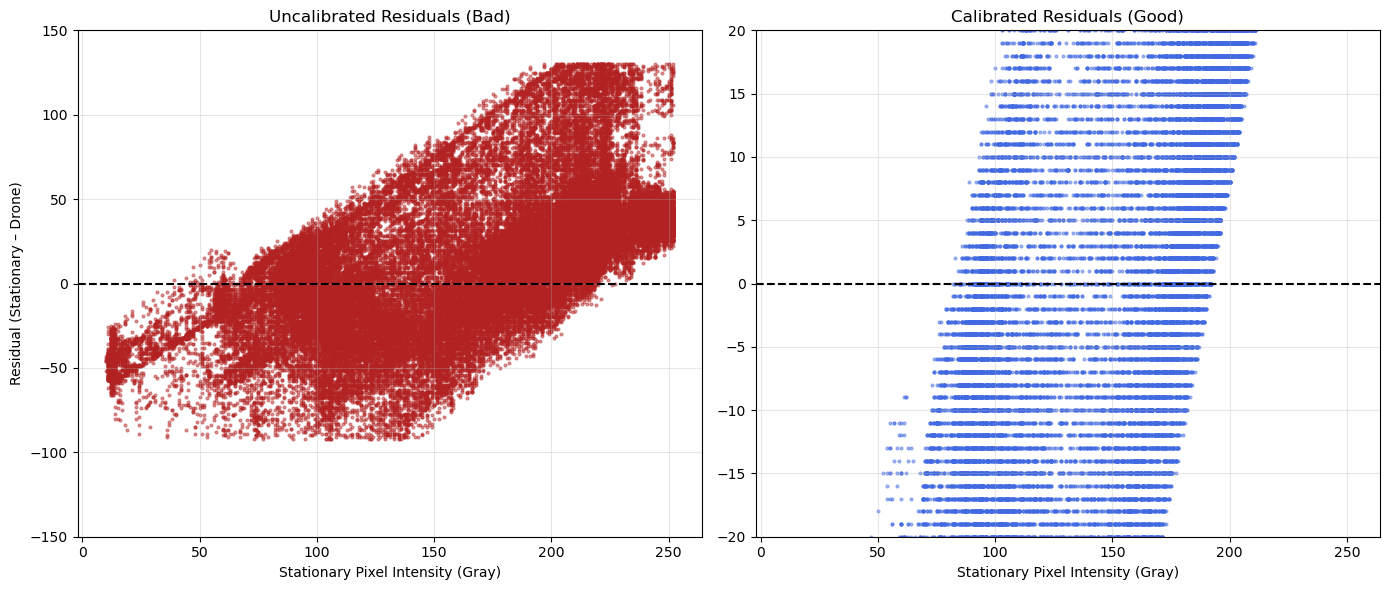

In [36]:
plt.figure(figsize=(14,6))

# ---------------- Uncalibrated ----------------
plt.subplot(1,2,1)
plt.scatter(X_raw_trim, raw_trim, s=4, alpha=0.45, color="firebrick")
plt.axhline(0, linestyle="--", color="black")
plt.ylim(raw_ylim)
plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.ylabel("Residual (Stationary – Drone)")
plt.title("Uncalibrated Residuals (Bad)")
plt.grid(alpha=0.3)

# ---------------- Calibrated ----------------
plt.subplot(1,2,2)
plt.scatter(X_cal_trim, cal_trim, s=4, alpha=0.45, color="royalblue")
plt.axhline(0, linestyle="--", color="black")
plt.ylim(cal_ylim)
plt.xlabel("Stationary Pixel Intensity (Gray)")
plt.title("Calibrated Residuals (Good)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
